# Physics constraints in a VAE for household electricity profiles

Can a variational autoencoder (VAE) generate realistic daily electricity profiles that obey basic physics
(power ≥ 0, power ≤ meter capacity)? This notebook trains a VAE on real data from one household and compares
an unconstrained baseline with a soft constraint (loss penalty) and two hard constraints (sigmoid, softplus).

Data preparation (hourly resampling, one row per day) is in `01_data.ipynb`. See `README.md` for the summary.

In [1]:
import torch
print(torch.__version__)

2.8.0


## 1. Data and train/test split
Days from 2006–2009 are used for training and 2010 for testing (a time-based split, so no information leaks
from the future). Values are divided by the largest training value so they lie roughly between 0 and 1.

In [2]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)   # makes results repeatable

days = pd.read_csv("data/days.csv", index_col=0, parse_dates=True)

# Split by time: learn from 2006–2009, test on 2010
train = days[days.index < "2010-01-01"]
test = days[days.index >= "2010-01-01"]

# Scale to roughly 0–1. Neural networks train better on small numbers
SCALE = train.values.max()
x_train = torch.tensor(train.values / SCALE, dtype=torch.float32)
x_test = torch.tensor(test.values / SCALE, dtype=torch.float32)

print("SCALE (kW):", SCALE)
print(x_train.shape, x_test.shape)

SCALE (kW): 6.560533333333334
torch.Size([1103, 24]) torch.Size([314, 24])


## 2. The VAE
The encoder compresses a day (24 hourly values) into 4 latent numbers; the decoder rebuilds the day.
The loss is reconstruction error + β · KL divergence. The baseline decoder has no output activation,
so nothing stops it from producing negative power.

In [3]:
class VAE(nn.Module):
    def __init__(self, latent_dim=4, hidden=64):
        super().__init__()
        # Encoder: 24 numbers -> hidden features
        self.encoder = nn.Sequential(
            nn.Linear(24, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
        )
        # Two "heads": the centre (mu) and the uncertainty (logvar) of each latent number
        self.to_mu = nn.Linear(hidden, latent_dim)
        self.to_logvar = nn.Linear(hidden, latent_dim)
        # Decoder: latent numbers -> 24 numbers
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 24),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.to_mu(h), self.to_logvar(h)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        std = torch.exp(0.5 * logvar)
        z = mu + std * torch.randn_like(std)   # the "reparameterisation trick"
        return self.decode(z), mu, logvar

In [4]:
def vae_loss(x, x_hat, mu, logvar, beta):
    # 1. Reconstruction: how different is the rebuilt day from the real one?
    recon = ((x - x_hat) ** 2).sum(dim=1).mean()
    # 2. KL divergence: how far are the latent codes from plain random noise N(0, 1)?
    kl = (-0.5 * (1 + logvar - mu**2 - logvar.exp()).sum(dim=1)).mean()
    return recon + beta * kl, recon, kl

Quick check that the shapes fit together, using 5 days and an untrained model:

In [5]:
model = VAE()
x_hat, mu, logvar = model(x_train[:5])       # push 5 real days through the untrained model
loss, recon, kl = vae_loss(x_train[:5], x_hat, mu, logvar, beta=0.003)
print("output shape:", x_hat.shape)
print("mu shape:", mu.shape)
print("loss:", loss.item())

output shape: torch.Size([5, 24])
mu shape: torch.Size([5, 4])
loss: 2.479785919189453


### Training
150 epochs (a first run showed the test error stops improving well before this). The training error is
averaged over each whole epoch.

In [6]:
BETA = 0.003
model = VAE()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loader = torch.utils.data.DataLoader(x_train, batch_size=64, shuffle=True)

history = []
for epoch in range(150):                         # CHANGED: 300 -> 150
    model.train()
    epoch_recon = 0.0                            # NEW: running total for this epoch
    for xb in loader:
        x_hat, mu, logvar = model(xb)
        loss, recon, kl = vae_loss(xb, x_hat, mu, logvar, BETA)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_recon += recon.item() * len(xb)    # NEW: add up this batch's error
    epoch_recon /= len(x_train)                  # NEW: average over all training days

    # check on the test year (no learning here)
    model.eval()
    with torch.no_grad():
        x_hat, mu, logvar = model(x_test)
        _, test_recon, test_kl = vae_loss(x_test, x_hat, mu, logvar, BETA)
    history.append((epoch_recon, test_recon.item(), kl.item()))   # CHANGED: epoch_recon

    if epoch % 25 == 0:
        print(f"epoch {epoch:3d} | train recon {epoch_recon:.4f} | test recon {test_recon.item():.4f} | KL {kl.item():.2f}")   # CHANGED: epoch_recon

torch.save(model.state_dict(), "vae_baseline.pt")

epoch   0 | train recon 0.8566 | test recon 0.4235 | KL 0.13
epoch  25 | train recon 0.1559 | test recon 0.1235 | KL 7.14
epoch  50 | train recon 0.1201 | test recon 0.1005 | KL 8.70
epoch  75 | train recon 0.1115 | test recon 0.1002 | KL 7.87
epoch 100 | train recon 0.1091 | test recon 0.1008 | KL 7.57
epoch 125 | train recon 0.1062 | test recon 0.1000 | KL 6.84


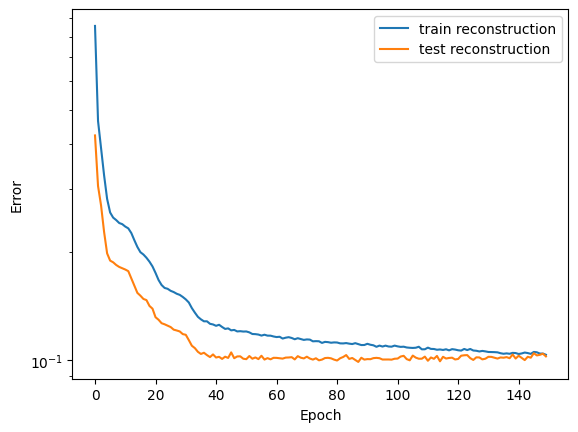

In [7]:
h = np.array(history)
plt.plot(h[:, 0], label="train reconstruction")
plt.plot(h[:, 1], label="test reconstruction")
plt.xlabel("Epoch")
plt.ylabel("Error")
plt.yscale("log")
plt.legend()
plt.show()

The test error ends slightly below the training error. The 2010 test days are less variable (and include no December):

In [8]:
print("Train days: mean %.2f kW, spread %.2f kW" % (train.values.mean(), train.values.std()))
print("Test days:  mean %.2f kW, spread %.2f kW" % (test.values.mean(), test.values.std()))

Train days: mean 1.10 kW, spread 0.93 kW
Test days:  mean 1.06 kW, spread 0.78 kW


## 3. Rebuilt days and generated days
First, can the VAE rebuild real test days? Then, generate brand-new days by decoding random codes z ~ N(0, I).

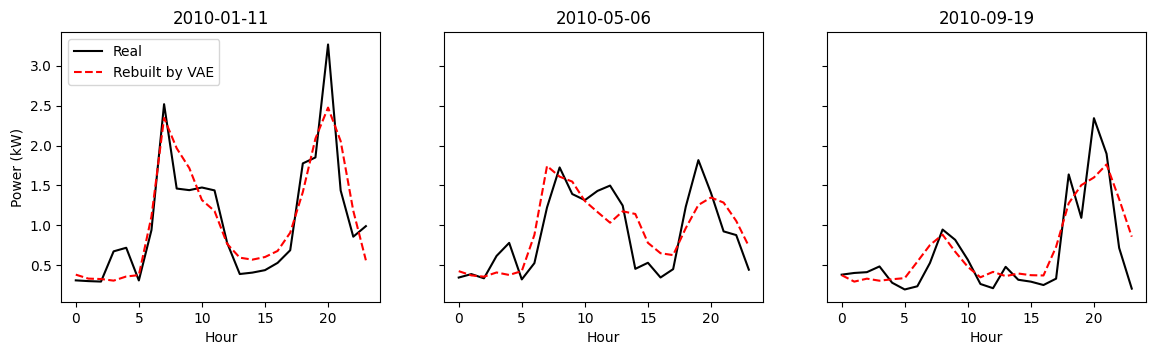

In [9]:
model.eval()
idx = [10, 120, 250]          # three test days: winter, spring, autumn
with torch.no_grad():
    mu, logvar = model.encode(x_test[idx])
    rebuilt = model.decode(mu).numpy() * SCALE   # use mu (the best guess), no randomness
original = x_test[idx].numpy() * SCALE

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, i, real_day, fake_day in zip(axes, idx, original, rebuilt):
    ax.plot(range(24), real_day, "k-", label="Real")
    ax.plot(range(24), fake_day, "r--", label="Rebuilt by VAE")
    ax.set_title(str(test.index[i].date()))
    ax.set_xlabel("Hour")
axes[0].set_ylabel("Power (kW)")
axes[0].legend()
plt.show()

In [10]:
torch.manual_seed(1)
with torch.no_grad():
    z = torch.randn(1000, 4)                     # 1,000 random codes from N(0, 1)
    fake = model.decode(z).numpy() * SCALE       # decoder turns each into a 24-hour day
real = train.values
print(fake.shape)

(1000, 24)


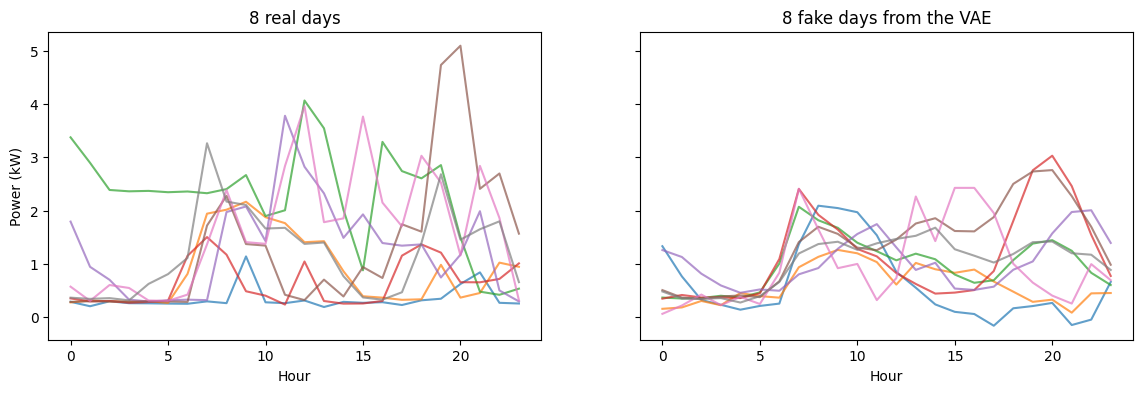

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
rng = np.random.default_rng(0)
for row in real[rng.choice(len(real), 8, replace=False)]:
    axes[0].plot(range(24), row, alpha=0.7)
for row in fake[:8]:
    axes[1].plot(range(24), row, alpha=0.7)
axes[0].set_title("8 real days")
axes[1].set_title("8 fake days from the VAE")
for ax in axes:
    ax.set_xlabel("Hour")
axes[0].set_ylabel("Power (kW)")
plt.show()

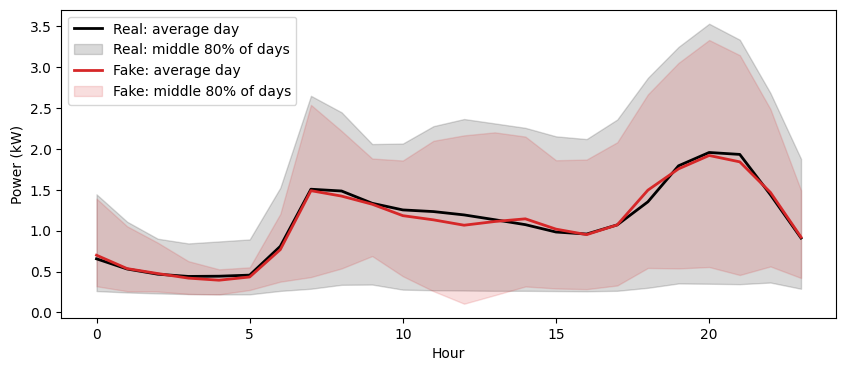

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
for data, name, colour in [(real, "Real", "black"), (fake, "Fake", "tab:red")]:
    ax.plot(range(24), data.mean(axis=0), color=colour, linewidth=2, label=f"{name}: average day")
    ax.fill_between(range(24),
                    np.percentile(data, 10, axis=0),
                    np.percentile(data, 90, axis=0),
                    color=colour, alpha=0.15, label=f"{name}: middle 80% of days")
ax.set_xlabel("Hour")
ax.set_ylabel("Power (kW)")
ax.legend()
plt.show()

Summary statistics for real vs generated days:

In [13]:
def summary(x):
    return {
        "mean power (kW)": x.mean(),
        "spread (kW)": x.std(),
        "energy per day (kWh)": x.sum(axis=1).mean(),
        "lowest hour (kW)": x.min(),
        "highest hour (kW)": x.max(),
        "bumpiness (kW)": np.abs(np.diff(x, axis=1)).mean(),
    }

print(pd.DataFrame({"Real": summary(real), "Fake": summary(fake)}).round(3))

                        Real    Fake
mean power (kW)        1.101   1.085
spread (kW)            0.928   0.800
energy per day (kWh)  26.417  26.046
lowest hour (kW)       0.124  -0.724
highest hour (kW)      6.561   5.910
bumpiness (kW)         0.452   0.289


## 4. Counting physics violations
Rule 1: power ≥ 0. Rule 2: power ≤ 11.1 kW, the highest one-minute reading in the data (the true contracted
limit is unknown, so this is a conservative cap). Measured on 10,000 generated days.

In [14]:
torch.manual_seed(2)
with torch.no_grad():
    fake_big = model.decode(torch.randn(10000, 4)).numpy() * SCALE   # 10,000 fake days

CAP_KW = 11.122   # highest one-minute reading ever recorded (Day 1)

def check_physics(x, cap=CAP_KW):
    negative = x < 0
    too_high = x > cap
    bad_day = (negative | too_high).any(axis=1)
    return {
        "% of hours below zero": 100 * negative.mean(),
        "% of hours above the cap": 100 * too_high.mean(),
        "% of days with any violation": 100 * bad_day.mean(),
        "lowest value (kW)": x.min(),
    }

print(pd.DataFrame({
    "Real days": check_physics(real),
    "Fake days (baseline)": check_physics(fake_big),
}).round(2))

                              Real days  Fake days (baseline)
% of hours below zero              0.00                  1.13
% of hours above the cap           0.00                  0.00
% of days with any violation       0.00                 10.86
lowest value (kW)                  0.12                 -1.73


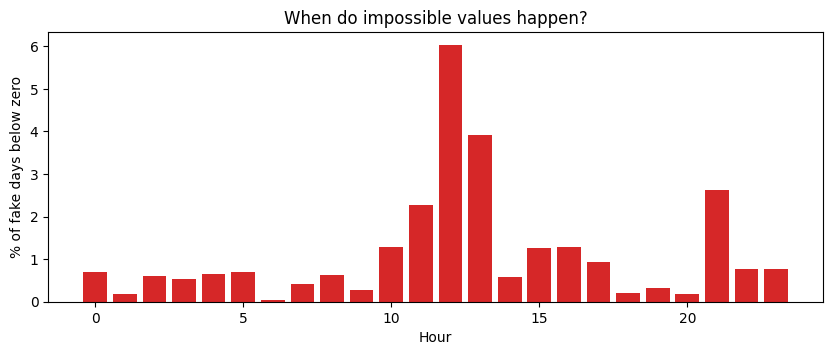

In [15]:
neg_by_hour = 100 * (fake_big < 0).mean(axis=0)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(range(24), neg_by_hour, color="tab:red")
ax.set_xlabel("Hour")
ax.set_ylabel("% of fake days below zero")
ax.set_title("When do impossible values happen?")
plt.show()

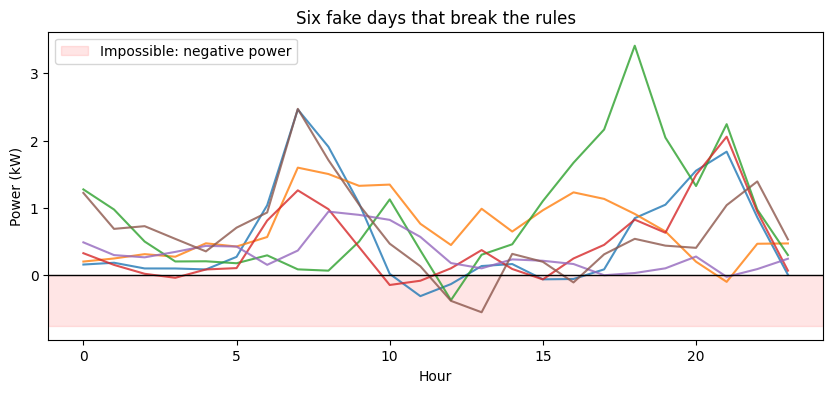

In [16]:
bad = np.where((fake_big < 0).any(axis=1))[0]

fig, ax = plt.subplots(figsize=(10, 4))
for i in bad[:6]:
    ax.plot(range(24), fake_big[i], alpha=0.8)
ax.axhspan(fake_big[bad[:6]].min() - 0.2, 0, color="red", alpha=0.1, label="Impossible: negative power")
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Hour")
ax.set_ylabel("Power (kW)")
ax.set_title("Six fake days that break the rules")
ax.legend()
plt.show()

## 5. Adding physics constraints
* **penalty**: extra loss term for outputs below 0 or above the cap (soft constraint)
* **sigmoid**: decoder output squashed into [0, cap] (hard constraint)
* **softplus**: decoder output forced above 0, no ceiling (hard constraint)

In [17]:
import torch.nn.functional as F

CAP_S = CAP_KW / SCALE

class PhysicsVAE(VAE):
    def __init__(self, mode="baseline", **kwargs):
        super().__init__(**kwargs)
        self.mode = mode

    def decode(self, z):
        out = self.decoder(z)
        if self.mode == "sigmoid":
            out = torch.sigmoid(out) * CAP_S   # between 0 and the cap
        elif self.mode == "softplus":
            out = F.softplus(out)              # always above 0, no ceiling
        return out

In [18]:
def physics_penalty(x_hat):
    below = torch.relu(-x_hat)          # how far below zero (0 if fine)
    above = torch.relu(x_hat - CAP_S)   # how far above the cap (0 if fine)
    return (below**2 + above**2).sum(dim=1).mean()

In [19]:
def train_model(mode, seed=0, beta=0.003, lam=100.0, epochs=150):
    torch.manual_seed(seed)
    model = PhysicsVAE(mode=mode)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = torch.utils.data.DataLoader(x_train, batch_size=64, shuffle=True)

    for epoch in range(epochs):
        model.train()
        for xb in loader:
            x_hat, mu, logvar = model(xb)
            loss, recon, kl = vae_loss(xb, x_hat, mu, logvar, beta)
            if mode == "penalty":
                loss = loss + lam * physics_penalty(x_hat)   # the only difference
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        x_hat, mu, logvar = model(x_test)
        _, test_recon, _ = vae_loss(x_test, x_hat, mu, logvar, beta)
    return model, test_recon.item()

## 6. Final experiment: 4 methods × 3 seeds
Each method is trained with 3 random seeds; 10,000 days are generated per model. **Energy gap** is the average
kWh difference between real and generated daily-energy distributions, compared percentile by percentile.

In [20]:
# ============ FINAL RESULTS (Day 6) ============
import os
os.makedirs("figures", exist_ok=True)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

def energy_gap(real, fake):
    """Average kWh difference between real and fake daily-energy distributions,
    compared percentile by percentile (1st, 2nd, ... 99th). 0 = identical."""
    q = np.arange(1, 100)
    return np.abs(np.percentile(real.sum(axis=1), q) - np.percentile(fake.sum(axis=1), q)).mean()

In [21]:
MODES = ["baseline", "penalty", "sigmoid", "softplus"]
final = []
final_samples = {}
for mode in MODES:
    for seed in [0, 1, 2]:
        m, test_recon = train_model(mode, seed)
        torch.manual_seed(100 + seed)
        with torch.no_grad():
            f = m.decode(torch.randn(10000, 4)).numpy() * SCALE
        final.append({"mode": mode, "seed": seed, "test recon": test_recon,
                      "energy gap (kWh)": energy_gap(real, f),
                      **check_physics(f), **summary(f)})
        if seed == 0:
            final_samples[mode] = f
            torch.save(m.state_dict(), f"vae_{mode}.pt")
        print(f"done: {mode}, seed {seed}")

final = pd.DataFrame(final)
final.to_csv("figures/results.csv", index=False)

done: baseline, seed 0
done: baseline, seed 1
done: baseline, seed 2
done: penalty, seed 0
done: penalty, seed 1
done: penalty, seed 2
done: sigmoid, seed 0
done: sigmoid, seed 1
done: sigmoid, seed 2
done: softplus, seed 0
done: softplus, seed 1
done: softplus, seed 2


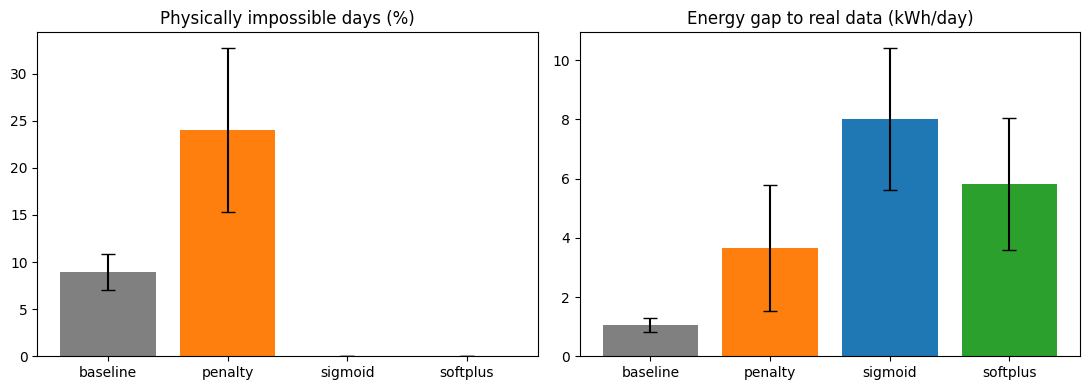

In [22]:
cols = ["% of days with any violation", "lowest value (kW)", "energy gap (kWh)",
        "energy per day (kWh)", "bumpiness (kW)", "test recon"]
mean = final.groupby("mode")[cols].mean()   # recalculated here from the final results
std = final.groupby("mode")[cols].std()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colours = ["grey", "tab:orange", "tab:blue", "tab:green"]
for ax, col, title in [(axes[0], "% of days with any violation", "Physically impossible days (%)"),
                       (axes[1], "energy gap (kWh)", "Energy gap to real data (kWh/day)")]:
    ax.bar(MODES, mean.loc[MODES, col], yerr=std.loc[MODES, col], capsize=5, color=colours)
    ax.set_title(title)
plt.tight_layout()
plt.savefig("figures/summary.png", dpi=150, bbox_inches="tight")
plt.show()

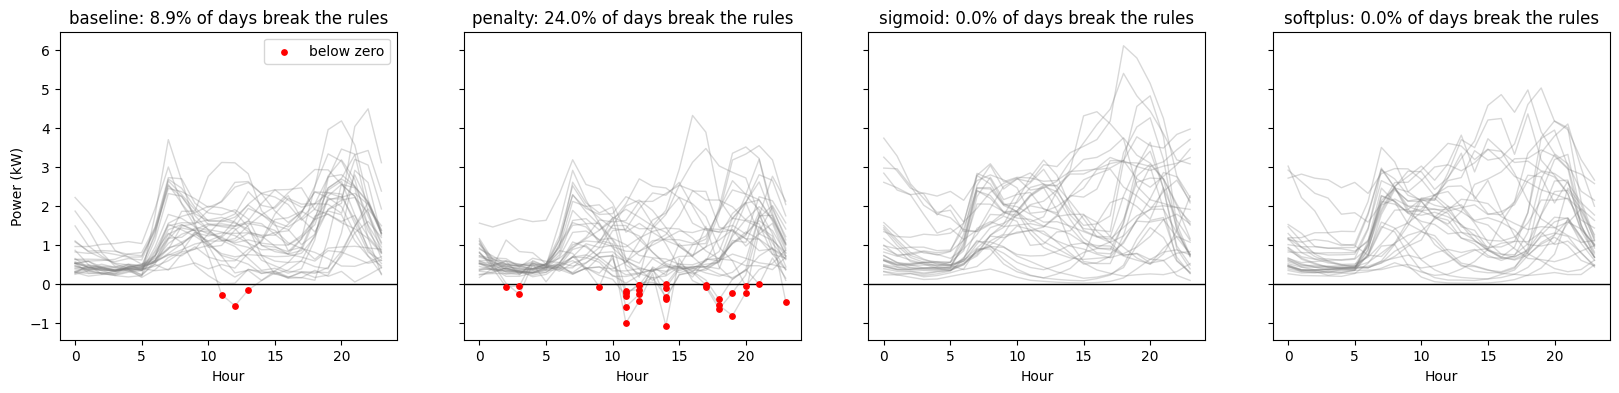

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, mode in zip(axes, MODES):
    s = final_samples[mode][:30]
    for row in s:
        ax.plot(range(24), row, color="grey", alpha=0.3, linewidth=1)
    bad_days, bad_hours = np.where(s < 0)
    ax.scatter(bad_hours, s[s < 0], color="red", s=15, zorder=3, label="below zero")
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(f"{mode}: {mean.loc[mode, '% of days with any violation']:.1f}% of days break the rules")
    ax.set_xlabel("Hour")
axes[0].set_ylabel("Power (kW)")
axes[0].legend()
plt.savefig("figures/methods_compared.png", dpi=150, bbox_inches="tight")
plt.show()

Results table in Markdown format (used in the README):

In [24]:
real_ref = {"% of days with any violation": "0", "lowest value (kW)": f"{real.min():.2f}",
            "energy gap (kWh)": "0", "energy per day (kWh)": f"{real.sum(axis=1).mean():.2f}",
            "bumpiness (kW)": f"{np.abs(np.diff(real, axis=1)).mean():.2f}", "test recon": "–"}
lines = ["| Metric | " + " | ".join(MODES) + " | Real data |",
         "|---|" + "---:|" * (len(MODES) + 1)]
for c in cols:
    row = [f"{mean.loc[m, c]:.2f} ± {std.loc[m, c]:.2f}" for m in MODES]
    lines.append(f"| {c} | " + " | ".join(row) + f" | {real_ref[c]} |")
print("\n".join(lines))

| Metric | baseline | penalty | sigmoid | softplus | Real data |
|---|---:|---:|---:|---:|---:|
| % of days with any violation | 8.91 ± 1.92 | 24.01 ± 8.74 | 0.00 ± 0.00 | 0.00 ± 0.00 | 0 |
| lowest value (kW) | -1.08 ± 0.10 | -1.34 ± 0.29 | 0.01 ± 0.01 | 0.01 ± 0.00 | 0.12 |
| energy gap (kWh) | 1.06 ± 0.24 | 3.66 ± 2.12 | 8.01 ± 2.41 | 5.81 ± 2.23 | 0 |
| energy per day (kWh) | 25.72 ± 0.45 | 23.01 ± 2.37 | 34.41 ± 2.41 | 32.23 ± 2.24 | 26.42 |
| bumpiness (kW) | 0.27 ± 0.00 | 0.29 ± 0.01 | 0.26 ± 0.02 | 0.27 ± 0.02 | 0.45 |
| test recon | 0.11 ± 0.00 | 0.10 ± 0.00 | 0.12 ± 0.02 | 0.11 ± 0.01 | – |


## 7. Diagnostics: why do the methods behave as they do?
**Penalty:** the penalty only acts on *rebuilt* training days. Do those go negative at all?

In [25]:
def recon_violations(model):
    with torch.no_grad():
        mu, logvar = model.encode(x_train)
        rebuilt = model.decode(mu).numpy() * SCALE
    return 100 * (rebuilt < 0).any(axis=1).mean()

for mode in ["baseline", "penalty"]:
    m = PhysicsVAE(mode=mode)
    m.load_state_dict(torch.load(f"vae_{mode}.pt"))
    m.eval()
    print(f"{mode}: {recon_violations(m):.2f}% of REBUILT training days go below zero")

baseline: 0.27% of REBUILT training days go below zero
penalty: 0.00% of REBUILT training days go below zero


**Energy bias:** are the hard-constrained models biased when rebuilding real days, or only when generating
from random codes? And how widely are the codes of real days spread compared with N(0, 1)?

In [26]:
print(f"Real training days: {real.sum(axis=1).mean():.1f} kWh/day\n")

for mode in ["baseline", "penalty", "sigmoid", "softplus"]:
    m = PhysicsVAE(mode=mode)
    m.load_state_dict(torch.load(f"vae_{mode}.pt"))
    m.eval()
    with torch.no_grad():
        mu, logvar = m.encode(x_train)
        rebuilt = m.decode(mu).numpy() * SCALE                       # from real codes
        torch.manual_seed(0)
        generated = m.decode(torch.randn(10000, 4)).numpy() * SCALE  # from random codes
    print(f"{mode:9s} | rebuilt: {rebuilt.sum(axis=1).mean():5.1f} kWh/day"
          f" | generated: {generated.sum(axis=1).mean():5.1f} kWh/day"
          f" | spread of real codes: {mu.std(dim=0).numpy().round(2)}")

Real training days: 26.4 kWh/day

baseline  | rebuilt:  26.8 kWh/day | generated:  26.4 kWh/day | spread of real codes: [0.93 0.97 0.98 0.94]
penalty   | rebuilt:  26.9 kWh/day | generated:  20.6 kWh/day | spread of real codes: [0.78 0.82 0.87 0.78]
sigmoid   | rebuilt:  26.0 kWh/day | generated:  36.7 kWh/day | spread of real codes: [0.78 0.7  0.9  0.85]
softplus  | rebuilt:  25.8 kWh/day | generated:  34.7 kWh/day | spread of real codes: [0.85 0.89 0.84 0.87]
